# Supplementary Exploration: Occupancy at \$3.25–\$4.25

This descriptive exploration examines locations in the stated price range using the full matched cross-section. It does not identify a causal price response or replace the report’s FLAT/TOD sample.

In [1]:
# Analysis of the occupancy dip between $3.25 and $4.25 price midpoints
# Goal: isolate the dip spaces, see which areas and streets they sit on,
# and compare them to the rest of the data.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


# --- Load data ---------------------------------------------------------------
# Use the matched project cross-section.
DATA_PATH = Path('../data/processed/parking_cross_section.csv')
df = pd.read_csv(DATA_PATH,dtype={'SpaceID': str, 'GEOID': str})


# --- Define the dip ----------------------------------------------------------
# dip range taken from the binned plot: occupancy drops from $3.25 to $4.25
DIP_LOW, DIP_HIGH = 3.25, 4.25

dip_df = df[df['price_midpoint'].between(DIP_LOW, DIP_HIGH)].copy()
rest_df = df[~df['price_midpoint'].between(DIP_LOW, DIP_HIGH)].copy()

print(f"Dip spaces: {len(dip_df)} | Rest: {len(rest_df)}")


# --- Area prefix (CB, CC, HO, LT, ...) ---------------------------------------
dip_df['area'] = dip_df['SpaceID'].str.extract(r'^([A-Z]+)')
rest_df['area'] = rest_df['SpaceID'].str.extract(r'^([A-Z]+)')


# --- Street names from BlockFace ("800 HOPE ST" -> "HOPE ST") ----------------
dip_df['street'] = dip_df['BlockFace'].str.replace(r'^\d+\s+', '', regex=True)


# --- Street summary for the dip ----------------------------------------------
street_summary = (
    dip_df.groupby('street')
    .agg(n_spaces=('SpaceID', 'count'),
         n_blocks=('BlockFace', 'nunique'),
         mean_occ=('occupancy_rate', 'mean'),
         prices=('price_midpoint', lambda s: sorted(s.unique())))
    .sort_values('n_spaces', ascending=False)
)

print("\nStreets in the dip:")
print(street_summary)

Dip spaces: 567 | Rest: 3572

Streets in the dip:
                                n_spaces  n_blocks  mean_occ  \
street                                                         
SANTEE ST                            102         9  0.511876   
MAPLE AVE                             80         8  0.546790   
WALL ST                               70         7  0.441379   
LOS ANGELES ST                        53         7  0.530192   
9TH ST                                51         8  0.519367   
OLYMPIC BLVD                          40         7  0.572020   
SAN JULIAN ST                         21         3  0.611384   
4TH ST                                20         2  0.626405   
11TH ST                               19         4  0.566693   
12TH ST                               16         2  0.480255   
8TH ST                                15         5  0.704473   
HILL ST                                8         1  0.604205   
SELMA AVE                              8         3  0.

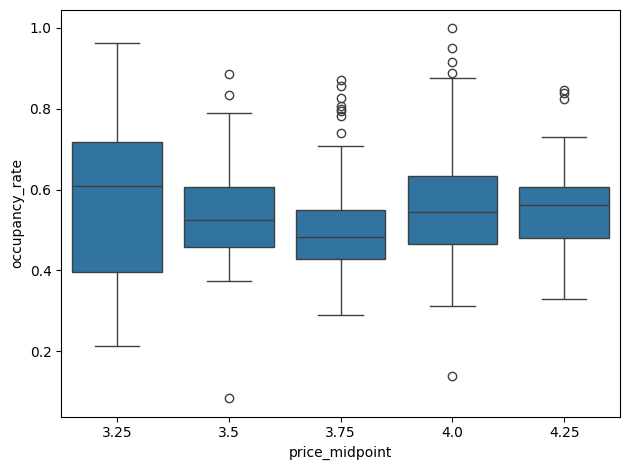

In [2]:
fig , ax = plt.subplots()
sns.boxplot(x = dip_df['price_midpoint'], y = dip_df['occupancy_rate'])
plt.tight_layout()
plt.show()


<Axes: xlabel='price_midpoint', ylabel='occupancy_rate'>

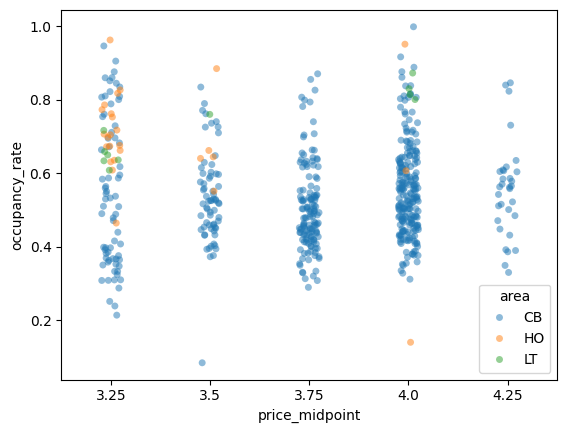

In [3]:
sns.stripplot(data=dip_df, x='price_midpoint', y='occupancy_rate', hue='area', alpha=0.5)

In [4]:
pd.concat({'dip': dip_df['area'].value_counts(normalize=True),
           'rest': rest_df['area'].value_counts(normalize=True)}, axis=1)

,dip,rest
area,,
CB,0.932384,0.496225
HO,0.048043,0.074623
LT,0.019573,0.059814
WV,NaN,0.099884
SV,NaN,0.087398
SP,NaN,0.063879
CT,NaN,0.046748
WP,NaN,0.026713
CC,NaN,0.026423
